# The function CAV on NT 2.5B — does a bigger nucleotide transformer help?

A copy of `Function CAV - Cross-Model, Region 8.ipynb` with one model: **`nt2p5b`**,
`InstaDeepAI/nucleotide-transformer-2.5b-multi-species`. Same company, same 6-mer tokenizer and same multi-species
data as nt500m; it differs mainly in size (32 layers, hidden 2560 vs 29 layers, hidden 1024). So a difference from
nt500m here is the cleanest test of "does scale help" that the cross-model comparison allows.

Everything else is unchanged: same sites, same motif-token readout (masked model, no reverse-complement pass), same
L2-logistic estimator. The output goes to `fcav_xm/nt2p5b_r{REGION}/fits/`, next to the other models, so Section 3
(AUC by depth, and motifbreakR with and without each model's CAV) puts it in the same tables as the rest.

**Every second layer only** (`stride = 2`: layers 0, 2, …, 32, 17 in all). Fitting costs grow with hidden², so all
33 layers would take ~7× nt500m's time; 17 layers is ~4×, roughly 8 h for region 8 on an A100. The fit loop resumes
per motif, so a disconnected session just picks up where it stopped. The nt500m self-check (2.3) is switched off: it
was passed already, and nt2p5b uses the same tokenizer path.

To run region 0 instead, set `REGION = 0` in 1.1, in the settings repeat of Section 2, and in 3.1.

---

# Section 1 — CPU: can every tokenizer do this at all?

Nothing here touches a model, so run it on a **CPU runtime** and do not spend a GPU on it. Both of its checks are
the ones most likely to fail, and both are free:

* **1.2** every model's tokens must tile the 600 bp window. A tokenizer without offset mapping, or a wrong resolver,
  stops here — before a GPU has been allocated.
* **1.3** the tokenisation-shape baseline for the BPE models, which every one of their later AUCs has to be read
  against.

In [ ]:
!pip install -q -U "transformers==4.57.6" "tokenizers==0.22.0" "huggingface_hub==0.34.0"
!pip install -q scikit-learn scipy pandas matplotlib

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

## 1.1 Settings and the model registry

`MODELS` is the list to run. Each entry says how to load the model and **how its tokens map to bases**, which is the
only thing the readout needs to know. `kmer` and `char` are arithmetic; `offsets` asks the tokenizer and requires a
fast tokenizer — Section 1.2 asserts that, rather than letting it fail silently halfway through a run.

In [ ]:
WORK_DIR = "/content/drive/MyDrive/GitHub/Biological-Foundation-Model/Notebooks/EP Pair Evaluation/per_occurrence/motif_token_study"
import os, json, time, gc
import numpy as np
import torch
import torch.nn.functional as F
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from transformers import AutoTokenizer, AutoModel, AutoConfig, AutoModelForMaskedLM, AutoModelForCausalLM

C = json.load(open(f"{WORK_DIR}/config.json"))
REGION = 8
REG = {0: "fcav_pgc_hk_r0", 8: "fcav_pgc_hk", 20: "fcav_pgc_hk_r20"}
SRC = f"{WORK_DIR}/{REG[REGION]}"
XM = f"{WORK_DIR}/fcav_xm"
os.makedirs(XM, exist_ok=True)

# tok_map: how a token index maps to bases.
#   kmer  k  -> token i covers bases [i*k, (i+1)*k)
#   char     -> token i covers base  [i, i+1)
#   offsets  -> ask the tokenizer (fast tokenizers only)
# loader: "hf" = AutoModel/AutoTokenizer; "evo2" = the ArcInstitute package, which has its own tokenizer and
# returns embeddings for NAMED layers instead of an output_hidden_states tuple.
REGISTRY = {
    "nt500m":    dict(hf="InstaDeepAI/nucleotide-transformer-v2-500m-multi-species", tok_map=("kmer", 6),  causal=False, loader="hf", batch=32),
    # NT v1 2.5B: native ESM in transformers, same 6-mer tokenizer as nt500m; every second layer (fitting ~ hidden^2)
    "nt2p5b":    dict(hf="InstaDeepAI/nucleotide-transformer-2.5b-multi-species",   tok_map=("kmer", 6),  causal=False, loader="hf", batch=16, stride=2),
    "hyenadna":  dict(hf="LongSafari/hyenadna-large-1m-seqlen-hf",                   tok_map=("char",),    causal=True,  loader="hf", batch=32, rc_mode="concat"),
    "dnabert2":  dict(hf="zhihan1996/DNABERT-2-117M",                                tok_map=("offsets",), causal=False, loader="hf", batch=32, out="dnabert2"),
    "genalm":    dict(hf="AIRI-Institute/gena-lm-bert-large-t2t",                    tok_map=("offsets",), causal=False, loader="hf", batch=32),
    "mistraldna":dict(hf="RaphaelMourad/Mistral-DNA-v1-422M-hg38",                   tok_map=("offsets",), causal=True,  loader="hf", batch=32, rc_mode="concat"),
    # Evo 2: byte tokenizer (one token per base) and next-token, so it uses the same `char` map and the same RC pass.
    # 7B is the one that runs in bfloat16 without Transformer Engine; 1B/20B/40B need FP8 and compute capability >= 8.9.
    # `layer_fmt` and `n_blocks` are confirmed by the smoke cell in 2.2 before any fitting.
    "evo2_7b":   dict(hf="arcinstitute/evo2_7b", tok_map=("char",), causal=True, loader="evo2", batch=4,
                      layer_fmt="blocks.{}.mlp.l3", n_blocks=32, stride=4, rc_mode="mean"),
}
# Cheapest first, so the first results arrive early and the one with an unknown cost is last. nt500m is omitted:
# `fcav_pgc_hk_lr` already holds that run and 2.3 only loads it to check this notebook reproduces it.
MODELS = ["nt2p5b"]
RC_FORCE = None           # None = each model decides from its `causal` flag. True/False overrides it, which
                          # Section 2.3 uses to ask what a second pass does to a MASKED model.
BASE_WEIGHTED = False     # equal weight to every token that touches the motif. With this off, the token set for a
                          # 6-mer model is exactly the legacy [K0, K1), so nt500m reproduces fcav_pgc_hk_lr exactly.
                          # It is a no-op for single-base models (hyenadna, evo2): every token is one base either way.
                          # Turn it on only together with a BPE model, where a token can hold 8 bases and clip 1.
BATCH = 32                # default per forward pass; a registry entry's `batch` overrides it
WLEN, MOFF = C["window_len"], C["motif_offset"]
DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")   # Section 1 runs on CPU
COMP = str.maketrans("ACGTN", "TGCAN")
rc = lambda s: s.translate(COMP)[::-1]
MWJ = json.load(open(f"{SRC}/mpra_windows.json"))
BUILT = sorted(m for m, s in MWJ["status"].items() if s == "built")
print(f"region {REGION}: {len(BUILT)} motifs with sites; models {MODELS}; base-weighted {BASE_WEIGHTED}")

## 1.2 Token-to-base mapping, and the check that it is right

For each model the window is tokenised once and every token is given the base interval it covers. The assertion that
matters is that those intervals **tile the whole window with no gap and no overlap** — if a resolver is wrong, the
covered length will not be 600 and the run stops here rather than producing quiet nonsense.

`span_weights` then turns a base interval into a vector of per-token weights: the number of the token's bases inside
the motif (or 1 for any token that touches it, when `BASE_WEIGHTED` is off).

In [ ]:
def load_tokenizer(tag):
    spec = REGISTRY[tag]
    tokz = AutoTokenizer.from_pretrained(spec["hf"], trust_remote_code=True)
    tokz.padding_side = "right"          # several of these default to left (Mistral, HyenaDNA)
    if tokz.pad_token is None:           # Mistral/Llama-style tokenizers ship without one, and padding=True then fails
        tokz.pad_token = tokz.eos_token if tokz.eos_token is not None else tokz.unk_token
    return tokz


def token_bases(spec, n):
    # (n, 2) base interval of each sequence token, for the arithmetic maps
    kind = spec["tok_map"][0]
    if kind == "kmer":
        k = spec["tok_map"][1]
        return np.stack([np.arange(n) * k, (np.arange(n) + 1) * k], 1)
    if kind == "char":
        return np.stack([np.arange(n), np.arange(n) + 1], 1)
    raise RuntimeError("offsets are resolved by the tokenizer, not here")


def encode(tokz, spec, seqs):
    # input_ids (B, T), attention mask (B, T) or None, and per sequence: the POSITIONS of its sequence tokens in
    # input_ids, and the base interval each one covers. Positions are read off the tokenizer and never assumed to
    # start at a fixed offset, so padding side, special tokens and zero-width tokens cannot shift the readout.
    kind = spec["tok_map"][0]
    if spec.get("loader") == "evo2":
        ids = torch.tensor([tokz.tokenize(x) for x in seqs], dtype=torch.int)
        assert ids.shape[1] == len(seqs[0]), f"evo2 tokenised {len(seqs[0])} bp into {ids.shape[1]} tokens"
        n = ids.shape[1]
        return ids, None, [np.arange(n)] * len(seqs), [token_bases(spec, n)] * len(seqs)
    if kind == "offsets":
        assert tokz.is_fast, f"{spec['hf']} has no fast tokenizer, so offset mapping is unavailable"
        enc = tokz(seqs, return_tensors="pt", padding=True, return_offsets_mapping=True)
    else:
        enc = tokz(seqs, return_tensors="pt", padding=True)
    ids = enc["input_ids"]
    am = enc.get("attention_mask")
    if am is None:
        am = (ids != tokz.pad_token_id).long()
    amn = am.numpy()
    pos, spans = [], []
    if kind == "offsets":
        om = enc["offset_mapping"].numpy()
        for b in range(len(seqs)):
            keep = (om[b, :, 1] > om[b, :, 0]) & (amn[b] == 1)
            pos.append(np.flatnonzero(keep))
            spans.append(om[b, keep])
    else:
        for b in range(len(seqs)):
            sp = np.array(tokz.get_special_tokens_mask(ids[b].tolist(), already_has_special_tokens=True))
            p = np.flatnonzero((sp == 0) & (amn[b] == 1))
            pos.append(p)
            spans.append(token_bases(spec, len(p)))
        assert len({len(p) for p in pos}) == 1, (
            f"{spec['hf']}: windows of equal length gave different token counts -- an N splits a 6-mer into "
            f"single bases, which the arithmetic map cannot follow")
    return ids, am, pos, spans


def span_weights(bases, lo, hi):
    # per-token weight for the base interval [lo, hi)
    ov = np.minimum(bases[:, 1], hi) - np.maximum(bases[:, 0], lo)
    ov = np.clip(ov, 0, None).astype(np.float32)
    if not BASE_WEIGHTED:
        ov = (ov > 0).astype(np.float32)
    assert ov.sum() > 0, f"no token covers bases [{lo}, {hi})"
    return ov / ov.sum()


def load_model(tag):
    spec = REGISTRY[tag]
    if spec.get("loader") == "evo2":
        from evo2 import Evo2
        return Evo2(spec["hf"].split("/")[-1])
    # Load the class the checkpoint ships its own code for. NT-v2's auto_map has AutoModelForMaskedLM but no
    # AutoModel, so a plain AutoModel falls back to transformers' built-in EsmModel, whose MLP has no gate -- the
    # "8192 vs 4096" size mismatch. AutoModel is still preferred where it exists (DNABERT-2's tuple-returning
    # BertModel is what the dnabert2 branch of hidden_stack expects).
    amap = getattr(AutoConfig.from_pretrained(spec["hf"], trust_remote_code=True), "auto_map", None) or {}
    cls = next((c for k, c in (("AutoModel", AutoModel), ("AutoModelForMaskedLM", AutoModelForMaskedLM),
                               ("AutoModelForCausalLM", AutoModelForCausalLM)) if k in amap), AutoModel)
    mdl = cls.from_pretrained(spec["hf"], trust_remote_code=True).to(DEV).eval()
    # DNABERT-2 ships a triton flash-attention kernel written for an old triton (`tl.dot(..., trans_b=True)`), which
    # current triton refuses to compile. Its code falls back to plain PyTorch attention when that kernel is None, so
    # switch it off in whichever of the model's own modules defines it. A no-op for every other model.
    import sys
    for name in {type(m).__module__ for m in mdl.modules()}:
        mod = sys.modules.get(name)
        if mod is not None and getattr(mod, "flash_attn_qkvpacked_func", None) is not None:
            mod.flash_attn_qkvpacked_func = None
            print(f"{tag}: triton flash-attention disabled in {name.split('.')[-1]}; using PyTorch attention")
    if spec.get("out") == "dnabert2" and getattr(mdl, "pooler", None) is not None:
        # with output_all_encoded_layers=True even the last layer comes back unpadded, (tokens, H), and the pooler's
        # hidden[:, 0] then takes a column instead of the CLS row and crashes. Its output is never used here.
        mdl.pooler = None
    return mdl


@torch.no_grad()
def hidden_stack(tag, model, ids, am):
    # one (layers, T_j, H) float tensor per sequence, whatever the architecture returns
    spec = REGISTRY[tag]
    if spec.get("loader") == "evo2":
        names = [spec["layer_fmt"].format(i) for i in SEL[tag]]
        _, emb = model(ids.to(DEV), return_embeddings=True, layer_names=names)
        S = torch.stack([emb[n] for n in names], 1).float()
        return [S[j] for j in range(S.shape[0])]
    if spec.get("out") == "dnabert2":
        # DNABERT-2's remote BertModel swallows output_hidden_states and returns a tuple; every layer needs
        # output_all_encoded_layers=True, and its intermediate layers come back with the padding REMOVED (one flat
        # (tokens, H) block per batch). One unpadded sequence at a time makes each layer that sequence's tokens in
        # order. Right padding (load_tokenizer) keeps the encode positions valid after the pads are cut.
        out = []
        for j in range(ids.shape[0]):
            t = ids[j][am[j].bool()][None].to(DEV)
            layers, _ = model(t, attention_mask=torch.ones_like(t), output_all_encoded_layers=True)
            out.append(torch.stack([x.reshape(t.shape[1], -1) for x in layers], 0).float())
        return out
    kw = {} if spec["causal"] else {"attention_mask": am.to(DEV)}   # a masked model must not attend to the pads;
    hs = model(input_ids=ids.to(DEV), output_hidden_states=True, **kw).hidden_states   # right-padded causal ones can't
    if tag in SEL:                                    # only the layers that will be fitted (stride)
        hs = [hs[i] for i in SEL[tag]]
    S = torch.stack(hs, 1).float()
    return [S[j] for j in range(S.shape[0])]


SEL, DEPTH, LOADED = {}, {}, {}
PROBE = [h["window"] for h in MWJ["hits"][:4]]       # real windows: a repeat like ACGT... tokenises atypically under BPE
for tag in MODELS:
    spec = REGISTRY[tag]
    if spec.get("loader") == "evo2":
        print(f"{tag:11s} {spec['tok_map'][0]:8s} causal {str(spec['causal']):5s}  evo2: checked in 2.2, not here")
        continue
    tokz = load_tokenizer(tag)
    ids, am, pos, spans = encode(tokz, spec, PROBE)
    for b in spans:
        assert b[0, 0] == 0 and b[-1, 1] == WLEN, f"{tag}: tokens cover [{b[0, 0]}, {b[-1, 1]}), expected [0, {WLEN})"
        assert (b[1:, 0] == b[:-1, 1]).all(), f"{tag}: token base intervals are not contiguous"
    w = span_weights(spans[0], MOFF, MOFF + 12)
    LOADED[tag] = dict(spec=spec, tokz=tokz)
    print(f"{tag:11s} {spec['tok_map'][0]:8s} causal {str(spec['causal']):5s}  "
          f"{min(len(p) for p in pos)}-{max(len(p) for p in pos)} tokens for {WLEN} bp  "
          f"a 12 bp motif touches {int((w > 0).sum())} of them  pad side {tokz.padding_side}")

## 1.3 Can the tokenisation alone tell bound from unbound?

Three of the four models tokenise with BPE, and BPE merges are learned from corpus frequency — so a GC-rich or
CpG-rich window is cut differently from an AT-rich one. The sites were matched on PWM, GC and CpG, but **matching
composition does not match tokenisation**. If bound sites are systematically cut into fewer or longer tokens, the span
shape itself leaks the label and a function direction fitted on those tokens could be reading the tokenizer.

So, before the models are run: a logistic on three numbers per site that use **no hidden state at all** — how many
tokens cover the motif, and how many bases each end spills outside it. If that alone reaches AUC ~0.65, a function
AUC of 0.68 from the same model means nothing and the fix is to add the token count to the matching variables.

Char-level models (hyenadna, evo2) are skipped: their span is the motif's bases exactly, with zero spill and no
variation, so there is nothing to leak.

In [ ]:
from sklearn.linear_model import LogisticRegression as _LR

SHAPE_MOTIFS = 6          # motifs to check; the confound is a property of the tokenizer, not of one motif


def span_shape(tag, seqs, lo, hi):
    # per sequence: (tokens covering [lo, hi), bases spilled left, bases spilled right)
    spec, tokz, out = REGISTRY[tag], LOADED[tag]["tokz"], []
    for i in range(0, len(seqs), 256):
        _, _, _, spans = encode(tokz, spec, seqs[i:i + 256])
        for b in spans:
            ov = np.minimum(b[:, 1], hi) - np.maximum(b[:, 0], lo)
            k = np.flatnonzero(ov > 0)
            out.append((len(k), lo - b[k[0], 0], b[k[-1], 1] - hi))
    return np.array(out, float)


bpe = [t for t in MODELS if REGISTRY[t]["tok_map"][0] == "offsets"]
if bpe:
    print(f"{'model':11s} {'motif':10s} {'sites':>6s} {'tokens':>7s} {'spill L':>8s} {'spill R':>8s} {'AUC shape':>10s}")
    for tag in bpe:
        if tag not in LOADED:
            LOADED[tag] = dict(spec=REGISTRY[tag], tokz=load_tokenizer(tag))
        worst = 0.0
        for m in BUILT[:SHAPE_MOTIFS]:
            J = json.load(open(f"{SRC}/sites/{m}.json"))
            R = J["records"]
            y = np.array([r["cls"] for r in R])
            w = int(J.get("width", (J["K1"] - J["K0"]) * 6))
            F3 = span_shape(tag, [r["window"] for r in R], MOFF, MOFF + w)
            oof = np.zeros(len(y))
            for tr, te in StratifiedKFold(5, shuffle=True, random_state=C["seed"]).split(F3, y):
                oof[te] = _LR(max_iter=1000).fit(F3[tr], y[tr]).decision_function(F3[te])
            a = roc_auc_score(y, oof)
            worst = max(worst, a)
            print(f"{tag:11s} {m:10s} {len(y):6d} {F3[:, 0].mean():7.2f} {F3[:, 1].mean():8.2f} "
                  f"{F3[:, 2].mean():8.2f} {a:10.3f}")
        print(f"{tag}: worst-case tokenisation-only AUC {worst:.3f}\n")
    print("Read every function AUC from these models against the number above. Close to 0.5 means the span shape is")
    print("uninformative and the readout is clean; 0.6+ means the tokenizer is a confound and the matching needs it.")
else:
    print("no BPE model in MODELS; nothing to check")

In [ ]:
from google.colab import runtime
runtime.unassign()

---

# Section 2 — GPU: embed and fit

From here a GPU is needed. Section 1 must have passed first: this section repeats its settings and its token
checks (cheap, tokenizers only) so the session is self-contained.

In [ ]:
!pip install -q -U "transformers==4.57.6" "tokenizers==0.22.0" "huggingface_hub==0.34.0" "safetensors==0.4.5"
!pip install -q scikit-learn scipy pandas matplotlib

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

In [ ]:
WORK_DIR = "/content/drive/MyDrive/GitHub/Biological-Foundation-Model/Notebooks/EP Pair Evaluation/per_occurrence/motif_token_study"
import os, json, time, gc
import numpy as np
import torch
import torch.nn.functional as F
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from transformers import AutoTokenizer, AutoModel, AutoConfig, AutoModelForMaskedLM, AutoModelForCausalLM

C = json.load(open(f"{WORK_DIR}/config.json"))
REGION = 8
REG = {0: "fcav_pgc_hk_r0", 8: "fcav_pgc_hk", 20: "fcav_pgc_hk_r20"}
SRC = f"{WORK_DIR}/{REG[REGION]}"
XM = f"{WORK_DIR}/fcav_xm"
os.makedirs(XM, exist_ok=True)

# tok_map: how a token index maps to bases.
#   kmer  k  -> token i covers bases [i*k, (i+1)*k)
#   char     -> token i covers base  [i, i+1)
#   offsets  -> ask the tokenizer (fast tokenizers only)
# loader: "hf" = AutoModel/AutoTokenizer; "evo2" = the ArcInstitute package, which has its own tokenizer and
# returns embeddings for NAMED layers instead of an output_hidden_states tuple.
REGISTRY = {
    "nt500m":    dict(hf="InstaDeepAI/nucleotide-transformer-v2-500m-multi-species", tok_map=("kmer", 6),  causal=False, loader="hf", batch=32),
    # NT v1 2.5B: native ESM in transformers, same 6-mer tokenizer as nt500m; every second layer (fitting ~ hidden^2)
    "nt2p5b":    dict(hf="InstaDeepAI/nucleotide-transformer-2.5b-multi-species",   tok_map=("kmer", 6),  causal=False, loader="hf", batch=16, stride=2),
    "hyenadna":  dict(hf="LongSafari/hyenadna-large-1m-seqlen-hf",                   tok_map=("char",),    causal=True,  loader="hf", batch=32, rc_mode="concat"),
    "dnabert2":  dict(hf="zhihan1996/DNABERT-2-117M",                                tok_map=("offsets",), causal=False, loader="hf", batch=32, out="dnabert2"),
    "genalm":    dict(hf="AIRI-Institute/gena-lm-bert-large-t2t",                    tok_map=("offsets",), causal=False, loader="hf", batch=32),
    "mistraldna":dict(hf="RaphaelMourad/Mistral-DNA-v1-422M-hg38",                   tok_map=("offsets",), causal=True,  loader="hf", batch=32, rc_mode="concat"),
    # Evo 2: byte tokenizer (one token per base) and next-token, so it uses the same `char` map and the same RC pass.
    # 7B is the one that runs in bfloat16 without Transformer Engine; 1B/20B/40B need FP8 and compute capability >= 8.9.
    # `layer_fmt` and `n_blocks` are confirmed by the smoke cell in 2.2 before any fitting.
    "evo2_7b":   dict(hf="arcinstitute/evo2_7b", tok_map=("char",), causal=True, loader="evo2", batch=4,
                      layer_fmt="blocks.{}.mlp.l3", n_blocks=32, stride=4, rc_mode="mean"),
}
# Cheapest first, so the first results arrive early and the one with an unknown cost is last. nt500m is omitted:
# `fcav_pgc_hk_lr` already holds that run and 2.3 only loads it to check this notebook reproduces it.
MODELS = ["nt2p5b"]
RC_FORCE = None           # None = each model decides from its `causal` flag. True/False overrides it, which
                          # Section 2.3 uses to ask what a second pass does to a MASKED model.
BASE_WEIGHTED = False     # equal weight to every token that touches the motif. With this off, the token set for a
                          # 6-mer model is exactly the legacy [K0, K1), so nt500m reproduces fcav_pgc_hk_lr exactly.
                          # It is a no-op for single-base models (hyenadna, evo2): every token is one base either way.
                          # Turn it on only together with a BPE model, where a token can hold 8 bases and clip 1.
BATCH = 32                # default per forward pass; a registry entry's `batch` overrides it
WLEN, MOFF = C["window_len"], C["motif_offset"]
DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")   # Section 1 runs on CPU
COMP = str.maketrans("ACGTN", "TGCAN")
rc = lambda s: s.translate(COMP)[::-1]
MWJ = json.load(open(f"{SRC}/mpra_windows.json"))
BUILT = sorted(m for m, s in MWJ["status"].items() if s == "built")
print(f"region {REGION}: {len(BUILT)} motifs with sites; models {MODELS}; base-weighted {BASE_WEIGHTED}")

In [ ]:
def load_tokenizer(tag):
    spec = REGISTRY[tag]
    tokz = AutoTokenizer.from_pretrained(spec["hf"], trust_remote_code=True)
    tokz.padding_side = "right"          # several of these default to left (Mistral, HyenaDNA)
    if tokz.pad_token is None:           # Mistral/Llama-style tokenizers ship without one, and padding=True then fails
        tokz.pad_token = tokz.eos_token if tokz.eos_token is not None else tokz.unk_token
    return tokz


def token_bases(spec, n):
    # (n, 2) base interval of each sequence token, for the arithmetic maps
    kind = spec["tok_map"][0]
    if kind == "kmer":
        k = spec["tok_map"][1]
        return np.stack([np.arange(n) * k, (np.arange(n) + 1) * k], 1)
    if kind == "char":
        return np.stack([np.arange(n), np.arange(n) + 1], 1)
    raise RuntimeError("offsets are resolved by the tokenizer, not here")


def encode(tokz, spec, seqs):
    # input_ids (B, T), attention mask (B, T) or None, and per sequence: the POSITIONS of its sequence tokens in
    # input_ids, and the base interval each one covers. Positions are read off the tokenizer and never assumed to
    # start at a fixed offset, so padding side, special tokens and zero-width tokens cannot shift the readout.
    kind = spec["tok_map"][0]
    if spec.get("loader") == "evo2":
        ids = torch.tensor([tokz.tokenize(x) for x in seqs], dtype=torch.int)
        assert ids.shape[1] == len(seqs[0]), f"evo2 tokenised {len(seqs[0])} bp into {ids.shape[1]} tokens"
        n = ids.shape[1]
        return ids, None, [np.arange(n)] * len(seqs), [token_bases(spec, n)] * len(seqs)
    if kind == "offsets":
        assert tokz.is_fast, f"{spec['hf']} has no fast tokenizer, so offset mapping is unavailable"
        enc = tokz(seqs, return_tensors="pt", padding=True, return_offsets_mapping=True)
    else:
        enc = tokz(seqs, return_tensors="pt", padding=True)
    ids = enc["input_ids"]
    am = enc.get("attention_mask")
    if am is None:
        am = (ids != tokz.pad_token_id).long()
    amn = am.numpy()
    pos, spans = [], []
    if kind == "offsets":
        om = enc["offset_mapping"].numpy()
        for b in range(len(seqs)):
            keep = (om[b, :, 1] > om[b, :, 0]) & (amn[b] == 1)
            pos.append(np.flatnonzero(keep))
            spans.append(om[b, keep])
    else:
        for b in range(len(seqs)):
            sp = np.array(tokz.get_special_tokens_mask(ids[b].tolist(), already_has_special_tokens=True))
            p = np.flatnonzero((sp == 0) & (amn[b] == 1))
            pos.append(p)
            spans.append(token_bases(spec, len(p)))
        assert len({len(p) for p in pos}) == 1, (
            f"{spec['hf']}: windows of equal length gave different token counts -- an N splits a 6-mer into "
            f"single bases, which the arithmetic map cannot follow")
    return ids, am, pos, spans


def span_weights(bases, lo, hi):
    # per-token weight for the base interval [lo, hi)
    ov = np.minimum(bases[:, 1], hi) - np.maximum(bases[:, 0], lo)
    ov = np.clip(ov, 0, None).astype(np.float32)
    if not BASE_WEIGHTED:
        ov = (ov > 0).astype(np.float32)
    assert ov.sum() > 0, f"no token covers bases [{lo}, {hi})"
    return ov / ov.sum()


def load_model(tag):
    spec = REGISTRY[tag]
    if spec.get("loader") == "evo2":
        from evo2 import Evo2
        return Evo2(spec["hf"].split("/")[-1])
    # Load the class the checkpoint ships its own code for. NT-v2's auto_map has AutoModelForMaskedLM but no
    # AutoModel, so a plain AutoModel falls back to transformers' built-in EsmModel, whose MLP has no gate -- the
    # "8192 vs 4096" size mismatch. AutoModel is still preferred where it exists (DNABERT-2's tuple-returning
    # BertModel is what the dnabert2 branch of hidden_stack expects).
    amap = getattr(AutoConfig.from_pretrained(spec["hf"], trust_remote_code=True), "auto_map", None) or {}
    cls = next((c for k, c in (("AutoModel", AutoModel), ("AutoModelForMaskedLM", AutoModelForMaskedLM),
                               ("AutoModelForCausalLM", AutoModelForCausalLM)) if k in amap), AutoModel)
    mdl = cls.from_pretrained(spec["hf"], trust_remote_code=True).to(DEV).eval()
    # DNABERT-2 ships a triton flash-attention kernel written for an old triton (`tl.dot(..., trans_b=True)`), which
    # current triton refuses to compile. Its code falls back to plain PyTorch attention when that kernel is None, so
    # switch it off in whichever of the model's own modules defines it. A no-op for every other model.
    import sys
    for name in {type(m).__module__ for m in mdl.modules()}:
        mod = sys.modules.get(name)
        if mod is not None and getattr(mod, "flash_attn_qkvpacked_func", None) is not None:
            mod.flash_attn_qkvpacked_func = None
            print(f"{tag}: triton flash-attention disabled in {name.split('.')[-1]}; using PyTorch attention")
    if spec.get("out") == "dnabert2" and getattr(mdl, "pooler", None) is not None:
        # with output_all_encoded_layers=True even the last layer comes back unpadded, (tokens, H), and the pooler's
        # hidden[:, 0] then takes a column instead of the CLS row and crashes. Its output is never used here.
        mdl.pooler = None
    return mdl


@torch.no_grad()
def hidden_stack(tag, model, ids, am):
    # one (layers, T_j, H) float tensor per sequence, whatever the architecture returns
    spec = REGISTRY[tag]
    if spec.get("loader") == "evo2":
        names = [spec["layer_fmt"].format(i) for i in SEL[tag]]
        _, emb = model(ids.to(DEV), return_embeddings=True, layer_names=names)
        S = torch.stack([emb[n] for n in names], 1).float()
        return [S[j] for j in range(S.shape[0])]
    if spec.get("out") == "dnabert2":
        # DNABERT-2's remote BertModel swallows output_hidden_states and returns a tuple; every layer needs
        # output_all_encoded_layers=True, and its intermediate layers come back with the padding REMOVED (one flat
        # (tokens, H) block per batch). One unpadded sequence at a time makes each layer that sequence's tokens in
        # order. Right padding (load_tokenizer) keeps the encode positions valid after the pads are cut.
        out = []
        for j in range(ids.shape[0]):
            t = ids[j][am[j].bool()][None].to(DEV)
            layers, _ = model(t, attention_mask=torch.ones_like(t), output_all_encoded_layers=True)
            out.append(torch.stack([x.reshape(t.shape[1], -1) for x in layers], 0).float())
        return out
    kw = {} if spec["causal"] else {"attention_mask": am.to(DEV)}   # a masked model must not attend to the pads;
    hs = model(input_ids=ids.to(DEV), output_hidden_states=True, **kw).hidden_states   # right-padded causal ones can't
    if tag in SEL:                                    # only the layers that will be fitted (stride)
        hs = [hs[i] for i in SEL[tag]]
    S = torch.stack(hs, 1).float()
    return [S[j] for j in range(S.shape[0])]


SEL, DEPTH, LOADED = {}, {}, {}
PROBE = [h["window"] for h in MWJ["hits"][:4]]       # real windows: a repeat like ACGT... tokenises atypically under BPE
for tag in MODELS:
    spec = REGISTRY[tag]
    if spec.get("loader") == "evo2":
        print(f"{tag:11s} {spec['tok_map'][0]:8s} causal {str(spec['causal']):5s}  evo2: checked in 2.2, not here")
        continue
    tokz = load_tokenizer(tag)
    ids, am, pos, spans = encode(tokz, spec, PROBE)
    for b in spans:
        assert b[0, 0] == 0 and b[-1, 1] == WLEN, f"{tag}: tokens cover [{b[0, 0]}, {b[-1, 1]}), expected [0, {WLEN})"
        assert (b[1:, 0] == b[:-1, 1]).all(), f"{tag}: token base intervals are not contiguous"
    w = span_weights(spans[0], MOFF, MOFF + 12)
    LOADED[tag] = dict(spec=spec, tokz=tokz)
    print(f"{tag:11s} {spec['tok_map'][0]:8s} causal {str(spec['causal']):5s}  "
          f"{min(len(p) for p in pos)}-{max(len(p) for p in pos)} tokens for {WLEN} bp  "
          f"a 12 bp motif touches {int((w > 0).sum())} of them  pad side {tokz.padding_side}")

## 2.1 The readout

One forward pass per batch, the span mean taken with those weights, and — when `RC` is on — a second pass over the
reverse complement, where the motif sits at `[WLEN − hi, WLEN − lo)`. The two are concatenated, so a direction fitted
here is `2 × hidden` long and the causal models are no longer reading one side only.

In [ ]:
@torch.no_grad()
def readout(tag, model, seqs, lohi):
    # (n, layers, D): D = hidden, or 2 * hidden for a causal model in concat mode; lohi[i] = the motif's bases
    L = LOADED[tag]
    tokz, spec = L["tokz"], L["spec"]
    use_rc = spec["causal"] if RC_FORCE is None else RC_FORCE
    passes = [(seqs, lohi)]
    if use_rc:
        passes.append(([rc(s) for s in seqs], [(WLEN - b, WLEN - a) for a, b in lohi]))
    bs = spec.get("batch", BATCH)
    parts = []
    for ss, lh in passes:
        out = None
        for i in range(0, len(ss), bs):
            chunk, lhc = ss[i:i + bs], lh[i:i + bs]
            ids, am, pos, spans = encode(tokz, spec, chunk)
            S = hidden_stack(tag, model, ids, am)                     # one (layers, T, H) per sequence
            if out is None:
                out = np.zeros((len(ss), S[0].shape[0], S[0].shape[2]), np.float16)
            for j in range(len(chunk)):
                w = torch.tensor(span_weights(spans[j], *lhc[j]), device=DEV)
                p = torch.tensor(pos[j], device=DEV)
                out[i + j] = (S[j][:, p] * w[None, :, None]).sum(1).half().cpu().numpy()
            del S
        parts.append(out)
    if len(parts) == 1:
        return parts[0]
    if spec.get("rc_mode", "concat") == "mean":
        return ((parts[0].astype(np.float32) + parts[1].astype(np.float32)) / 2).astype(np.float16)
    return np.concatenate(parts, 2)

## 2.2 Evo 2: does it load, what are its layers called, and how fast is it

Evo 2 does not go through `AutoModel`. It has its own package, its own byte tokenizer (one token per base, no special
tokens), and it returns embeddings for **named** layers instead of an `output_hidden_states` tuple. Only the 7B
checkpoint runs in bfloat16 without Transformer Engine; 1B, 20B and 40B need FP8 and compute capability >= 8.9, which
a Colab A100 (8.0) does not have.

Three things cannot be known without a real machine, so this cell settles all three and nothing below rests on a
guess: whether a 600 bp window really tokenises to 600 tokens, what the readable layers are actually called, and how
long a batch takes. **Set `layer_fmt`, `n_blocks` and `stride` in the registry from what it prints**, then put
`"evo2_7b"` into `MODELS`.

One caveat to settle from the printed names: `blocks.N.mlp.l3` is an MLP output, not the residual stream. If a
residual-stream name is available, prefer it -- it is the closer analogue of a `hidden_states` entry, and the whole
point of the depth plot is that the models are read at comparable places.

Skipped unless `EVO2_SMOKE` is true, so the rest of the notebook runs without the package installed.

In [ ]:
EVO2_SMOKE = False        # evo2 is not in MODELS yet; flip this when you want to resolve its API and cost


def prepare(tag):
    # load a model and settle, from one real forward pass, how many layers it returns and that every token position
    # the readout will index exists. The layer ids come from the model, not from a config attribute (HyenaDNA's
    # config has n_layer, not num_hidden_layers; DNABERT-2 returns no embedding-layer output).
    spec = REGISTRY[tag]
    mdl = load_model(tag)
    tokz = mdl.tokenizer if spec.get("loader") == "evo2" else LOADED.get(tag, {}).get("tokz") or load_tokenizer(tag)
    LOADED[tag] = dict(spec=spec, tokz=tokz)
    if spec.get("loader") == "evo2":
        nb = spec["n_blocks"]
        SEL[tag], DEPTH[tag] = sorted(set(range(0, nb, spec.get("stride", 1))) | {nb - 1}), nb - 1
    if spec.get("loader") != "evo2":
        SEL.pop(tag, None)                                # the probe reads every layer
    ids, am, pos, spans = encode(tokz, spec, PROBE[:2])
    S = hidden_stack(tag, mdl, ids, am)
    for j, Sj in enumerate(S):
        assert Sj.ndim == 3 and int(pos[j].max()) < Sj.shape[1], \
            f"{tag}: a (layers, T, H) tensor of shape {tuple(Sj.shape)} cannot hold token position {pos[j].max()}"
        b = spans[j]
        assert b[0, 0] == 0 and b[-1, 1] == WLEN and (b[1:, 0] == b[:-1, 1]).all(), f"{tag}: tokens do not tile"
    nl = S[0].shape[0]
    if spec.get("loader") != "evo2":
        if spec.get("out") == "dnabert2":
            SEL[tag], DEPTH[tag] = list(range(1, nl + 1)), nl
        else:
            SEL[tag], DEPTH[tag] = sorted(set(range(0, nl, spec.get("stride", 1))) | {nl - 1}), nl - 1
    assert spec.get("stride", 1) > 1 or len(SEL[tag]) == nl, f"{tag}: {nl} layers came back, {len(SEL[tag])} expected"
    print(f"{tag}: {nl} layers returned, {len(SEL[tag])} kept (depth {DEPTH[tag]}), hidden {S[0].shape[2]}, "
          f"{len(pos[0])} tokens for {WLEN} bp")
    del S
    return mdl


if EVO2_SMOKE:
    import time as _t
    spec = REGISTRY["evo2_7b"]
    from evo2 import Evo2
    ev = Evo2(spec["hf"].split("/")[-1])
    probe = "ACGT" * (WLEN // 4)
    ids = torch.tensor([ev.tokenizer.tokenize(probe)], dtype=torch.int)
    print(f"600 bp -> {ids.shape[1]} tokens   (must be 600 for the char map to be right)")

    inner = getattr(ev, "model", ev)
    names = [n for n, _ in inner.named_modules()]
    blocks = sorted({int(n.split(".")[1]) for n in names
                     if n.startswith("blocks.") and n.split(".")[1].isdigit()})
    print(f"{len(blocks)} blocks found: {blocks[0]}..{blocks[-1]}   (set n_blocks to {len(blocks)})")
    print("readable names inside the last block:")
    for n in sorted({x for x in names if x.startswith(f"blocks.{blocks[-1]}.")})[:25]:
        print("   ", n)

    want = spec["layer_fmt"].format(blocks[-1])
    assert want in names, f"{want} is not a module; pick one of the names above and set layer_fmt"
    _, emb = ev(ids.to(DEV), return_embeddings=True, layer_names=[want])
    e = emb[want]
    print(f"\n{want}: shape {tuple(e.shape)}  dtype {e.dtype}")
    assert e.shape[1] == ids.shape[1], "that layer does not give one vector per token"

    bs = spec.get("batch", 4)
    sel_names = [spec["layer_fmt"].format(i) for i in range(0, len(blocks), spec.get("stride", 1))]
    batch = torch.tensor([ev.tokenizer.tokenize(probe)] * bs, dtype=torch.int)
    torch.cuda.synchronize(); t0 = _t.time()
    ev(batch.to(DEV), return_embeddings=True, layer_names=sel_names)
    torch.cuda.synchronize(); dt = _t.time() - t0
    per = dt / bs
    print(f"\n{bs} sequences x {len(sel_names)} layers: {dt:.2f}s  ->  {per * 1000:.0f} ms per sequence per pass")
    print(f"with RC that is {2 * per:.3f}s per site; 3000 sites = {2 * per * 3000 / 60:.0f} min for one motif, "
          f"{2 * per * 3000 * 31 / 3600:.1f} h for 31")
    print("\nToo slow? raise stride, or cap the sites per motif. Fix the registry, then add evo2_7b to MODELS.")
    del ev; gc.collect(); torch.cuda.empty_cache()

## 2.3 The self-check, before anything is fitted

`nt500m` with `RC = False` and equal weights is exactly the readout the existing notebook used, so its AUCs must come
out the same. This refits two motifs both ways and prints the three numbers side by side. If the legacy column does
not reproduce `fcav_pgc_hk_lr`, the readout is wrong and nothing below is worth running; if the `RC = True` column
moves a lot on a **masked** model, the second pass is doing something other than filling in the right flank.

Set `CHECK = []` to skip it once it has passed.

In [ ]:
# The estimator, copied unchanged from `Function CAV - Strict Labels, PWM-GC-CpG-Matched L2 Logistic,
# Region 8.ipynb`: an L2 logistic path fitted for every layer at once by warm-started Newton steps,
# penalty chosen by inner CV. Verbatim, so a difference between models cannot come from the estimator.
if DEV.type == "cuda":
    torch.backends.cuda.preferred_linalg_library("cusolver")   # batched linalg.solve via cuBLAS fails on some Colab builds
LAMS = torch.logspace(4, -1, 11, device=DEV)      # L2 penalties tried, strongest first (standardised features, summed log-loss)
NEWTON = 15                                       # max Newton steps per penalty
INNER = 3                                         # inner CV folds for the penalty


def logit_path(X, y):
    # L2 logistic regression for every layer at once and every penalty in LAMS (warm-started, strongest first).
    # X: (layers, n, d) standardised; y: (n,) 0/1. Returns W (lams, layers, d + 1) = [weights, intercept].
    nl, n, d = X.shape
    Xa = torch.cat([X, torch.ones(nl, n, 1, device=X.device)], 2)
    pen = torch.ones(d + 1, device=X.device); pen[-1] = 0                # intercept not penalised
    eye = torch.eye(d + 1, device=X.device)
    w = torch.zeros(nl, d + 1, device=X.device)
    w[:, -1] = torch.logit(y.mean().clamp(1e-3, 1 - 1e-3))

    def loss(w, lam):
        z = torch.einsum("lnd,ld->ln", Xa, w)
        return F.binary_cross_entropy_with_logits(z, y.expand_as(z), reduction="none").sum(1) + lam / 2 * (pen * w * w).sum(1)

    out = []
    for lam in LAMS.tolist():
        for _ in range(NEWTON):
            z = torch.einsum("lnd,ld->ln", Xa, w)
            p = torch.sigmoid(z)
            g = torch.einsum("lnd,ln->ld", Xa, p - y) + lam * pen * w
            H = (Xa * (p * (1 - p))[..., None]).transpose(1, 2) @ Xa + torch.diag(lam * pen + 1e-6)
            # H is SPD in exact arithmetic, but in float32 a weakly penalised, strongly collinear readout can make it
            # numerically indefinite. cholesky_ex does not raise then: it returns a NaN factor and a flag, and the
            # original discarded the flag -- so the step was NaN, and even t = 0 gave w - 0 * NaN = NaN. Factorise in
            # float64, and let a layer whose factorisation still fails stand still instead of turning into NaN.
            Lc, info = torch.linalg.cholesky_ex(H.double())
            step = torch.cholesky_solve(g.double()[..., None], Lc)[..., 0].float()
            step = torch.where(torch.isfinite(step), step, torch.zeros_like(step))
            step[info > 0] = 0
            ts = torch.tensor([1, .5, .25, .125, 0], device=X.device)
            L = torch.stack([loss(w - t * step, lam) for t in ts])         # (steps, layers); t = 0 keeps w
            L = torch.nan_to_num(L, nan=float("inf"))                         # a NaN loss must never win
            t = ts[L.argmin(0)][:, None]
            w = w - t * step
            if (t * step).abs().max() < 1e-4:
                break
        out.append(w.clone())
    return torch.stack(out)


def bce(Xte, yte, W):
    # held-out summed log-loss of every (penalty, layer); Xte (layers, n, d), W (lams, layers, d + 1)
    z = torch.einsum("lnd,kld->kln", Xte, W[..., :-1]) + W[..., -1:]
    return F.binary_cross_entropy_with_logits(z, yte.expand_as(z), reduction="none").sum(2)


def fit_logit(X, y, seed):
    # penalty per layer by INNER-fold CV log-loss on these sites, then the model on all of them at that penalty.
    # Returns W (layers, d + 1), the chosen penalty index per layer, and the whole path.
    ll = torch.zeros(len(LAMS), X.shape[0], device=X.device)
    yn = y.cpu().numpy()
    for itr, ite in StratifiedKFold(INNER, shuffle=True, random_state=seed).split(np.zeros(len(yn)), yn):
        itr, ite = torch.tensor(itr, device=X.device), torch.tensor(ite, device=X.device)
        ll += bce(X[:, ite], y[ite], logit_path(X[:, itr], y[itr]))
    k = torch.nan_to_num(ll, nan=float("inf")).argmin(0)
    Wp = logit_path(X, y)
    return Wp[k, torch.arange(X.shape[0])], k.cpu().numpy(), Wp


def pct_of(ref, v):
    # percentile of each v among ref (ties count half), 0-100
    ref = np.sort(ref)
    lo, hi = np.searchsorted(ref, v, "left"), np.searchsorted(ref, v, "right")
    return 100 * (lo + hi) / 2 / len(ref)

In [ ]:
def fit_one(X, y, seed, Hh=None):
    # the existing protocol: 5 outer folds, penalty by inner CV, out-of-fold AUC per layer, hit logits per fold
    folds = list(StratifiedKFold(5, shuffle=True, random_state=seed).split(X, y))
    Xg = torch.tensor(X, dtype=torch.float32, device=DEV).transpose(0, 1).contiguous()
    yg = torch.tensor(y, dtype=torch.float32, device=DEV)
    Hg = None if Hh is None else torch.tensor(Hh, dtype=torch.float32, device=DEV).transpose(0, 1).contiguous()
    nl = Xg.shape[0]
    oof = np.zeros((len(y), nl), np.float32)
    dk, qk, kk = [], [], []
    for f, (tr, te) in enumerate(folds):
        mu, sd = Xg[:, tr].mean(1, keepdim=True), Xg[:, tr].std(1, keepdim=True) + 1e-6
        W, ki, _ = fit_logit((Xg[:, tr] - mu) / sd, yg[tr], seed + f)
        kk.append(ki)
        oof[te] = (torch.einsum("lnd,ld->ln", (Xg[:, te] - mu) / sd, W[:, :-1]) + W[:, -1:]).cpu().numpy().T
        if Hg is not None:
            dh = (torch.einsum("lnd,ld->ln", (Hg - mu) / sd, W[:, :-1]) + W[:, -1:]).cpu().numpy().T
            dk.append(dh); qk.append(1 / (1 + np.exp(-dh)))
    bad = ~np.isfinite(oof).all(0)
    assert not bad.any(), f"non-finite out-of-fold logits at layers {np.flatnonzero(bad).tolist()}"
    auc = np.array([roc_auc_score(y, oof[:, li]) for li in range(nl)])
    mu, sd = Xg.mean(1, keepdim=True), Xg.std(1, keepdim=True) + 1e-6
    Wp = logit_path((Xg - mu) / sd, yg)
    kall = np.median(np.array(kk), 0).round().astype(int)
    W = Wp[torch.tensor(kall, device=DEV), torch.arange(nl, device=DEV)]
    res = dict(auc=auc, oof=oof, cls=y, w_all=W.cpu().numpy(), mu=mu[:, 0].cpu().numpy(), sd=sd[:, 0].cpu().numpy(),
               lam_all=LAMS.cpu().numpy()[kall], layers=np.arange(nl))
    if Hg is not None:
        res["dec_hit"] = np.mean(dk, 0).astype(np.float32)
        res["prob_hit"] = np.mean(qk, 0).astype(np.float32)
    del Xg, Hg, Wp; gc.collect(); torch.cuda.empty_cache()
    return res


LEGACY_LR = {0: "fcav_pgc_hk_lr_r0", 8: "fcav_pgc_hk_lr", 20: "fcav_pgc_hk_lr_r20"}[REGION]
CHECK = []                # nt500m self-check: already passed, and nt2p5b uses the same tokenizer path
CHECK_RC = False          # also fit nt500m WITH a forced RC pass. Off by default: it is d = 2048, so it costs
                          # about four times the rest of this cell, and RC on a masked model is not the design.
if CHECK:
    _bw = BASE_WEIGHTED
    globals()["BASE_WEIGHTED"] = False     # the legacy readout is unweighted; force it here whatever the setting is
    mdl = prepare("nt500m")
    print(f"{'motif':10s} {'sites':>6s} {'legacy best':>12s} {'here RC=off':>12s} {'here RC=on':>11s}   layer of each")
    for m in CHECK:
        J = json.load(open(f"{SRC}/sites/{m}.json"))
        R = J["records"]
        y = np.array([r["cls"] for r in R])
        # With equal weights, the tokens overlapping [MOFF, MOFF + width) ARE the legacy [K0, K1), so this is
        # the old readout exactly -- the AUCs should match to fold noise, not approximately.
        w = int(J.get("width", (J["K1"] - J["K0"]) * 6))
        lohi = [(MOFF, MOFF + w)] * len(R)
        old = np.load(f"{WORK_DIR}/{LEGACY_LR}/fits/{m}.npz")["auc"]
        globals()["RC_FORCE"] = False
        a0 = fit_one(readout("nt500m", mdl, [r["window"] for r in R], lohi), y, C["seed"])["auc"]
        if CHECK_RC:
            globals()["RC_FORCE"] = True
            a1 = fit_one(readout("nt500m", mdl, [r["window"] for r in R], lohi), y, C["seed"])["auc"]
            print(f"{m:10s} {len(y):6d} {old.max():12.3f} {a0.max():12.3f} {a1.max():11.3f}   "
                  f"L{int(old.argmax())} / L{int(a0.argmax())} / L{int(a1.argmax())}")
        else:
            print(f"{m:10s} {len(y):6d} {old.max():12.3f} {a0.max():12.3f} {'-':>11s}   "
                  f"L{int(old.argmax())} / L{int(a0.argmax())}   max |AUC difference| over all layers "
                  f"{np.abs(old - a0).max():.4f}")
    print("\nthe legacy column and the RC=off column must agree to about 0.01; a gap means the span is resolved wrong.")
    print("a large move in the RC=on column on this MASKED model would mean it is not reverse-complement equivariant.")
    print("RC stays OFF for masked models either way: they already see both flanks, so a second pass only doubles the")
    print("feature width and the fitting cost, and makes the numbers incomparable with fcav_pgc_hk_lr.")
    globals()["RC_FORCE"], globals()["BASE_WEIGHTED"] = None, _bw
    del mdl; gc.collect(); torch.cuda.empty_cache()

## 2.4 Fit every model

One model loaded at a time, every motif of the region, resumable per `(model, motif)`. The output `.npz` carries the
same keys the hit-selection notebook reads — `dec_hit`, `hit_id`, `layers` — so pointing that notebook at
`fcav_xm/<tag>_r{REGION}` is the whole integration.

In [ ]:
H = MWJ["hits"]
t_all = time.time()
for tag in MODELS:
    OUT = f"{XM}/{tag}_r{REGION}/fits"
    os.makedirs(OUT, exist_ok=True)
    todo = [m for m in BUILT if not os.path.exists(f"{OUT}/{m}.npz")]
    print(f"\n=== {tag}: {len(todo)} of {len(BUILT)} motifs to do", flush=True)
    if not todo:
        continue
    mdl = prepare(tag)
    for k, m in enumerate(todo):
        t0 = time.time()
        J = json.load(open(f"{SRC}/sites/{m}.json"))
        R = J["records"]
        w = int(J.get("width", (J["K1"] - J["K0"]) * 6))   # the motif's own width in bases: every model reads the
                                                           # same bases, not whatever a 6-mer grid rounds up to
        y = np.array([r["cls"] for r in R])
        hi = [h for h in H if h["motif"] == m]
        if not hi:
            print(f"[{k + 1}/{len(todo)}] {m}: no hit in region {REGION}, skipped"); continue
        X = readout(tag, mdl, [r["window"] for r in R], [(MOFF, MOFF + w)] * len(R))
        XH = readout(tag, mdl, [h["window"] for h in hi], [(MOFF, MOFF + w)] * len(hi))
        assert np.isfinite(X).all() and np.isfinite(XH).all(), \
            f"{tag} {m}: a hidden state overflowed float16; store the readout as float32 for this model"
        res = fit_one(X, y, C["seed"], XH)
        res["layers"] = np.array(SEL[tag])          # the real layer ids, a subset for evo2
        np.savez(f"{OUT}/{m}.npz", hit_id=np.array([h["hit_id"] for h in hi]), n_layers=DEPTH[tag],
                 model=tag, rc=REGISTRY[tag]["causal"], rc_mode=REGISTRY[tag].get("rc_mode", "concat"),
                 base_weighted=BASE_WEIGHTED, **res)
        print(f"[{k + 1}/{len(todo)}] {m:10s} sites {len(y):5d} hits {len(hi):2d} dim {X.shape[2]:5d} "
              f"layers {X.shape[1]:3d}  AUC best L{int(res['auc'].argmax())} {res['auc'].max():.3f} "
              f"last {res['auc'][-1]:.3f}  [{time.time() - t0:.0f}s, {(time.time() - t_all) / 60:.1f} min]", flush=True)
        del X, XH; gc.collect(); torch.cuda.empty_cache()
    del mdl; gc.collect(); torch.cuda.empty_cache()
print(f"\ndone [{(time.time() - t_all) / 60:.1f} min]")

In [ ]:
from google.colab import runtime
runtime.unassign()

---

# Section 3 — CPU: the curves and the handover

Reading the fits back. No GPU.

In [6]:
!pip install -q -U "transformers==4.57.6" "tokenizers==0.22.0" "huggingface_hub==0.34.0"
!pip install -q scikit-learn scipy pandas matplotlib

In [7]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 3.1 Does it hold, and does it hold at the same depth?

Two questions, two panels. **Left:** out-of-fold AUC of the function direction against **relative depth**, averaged
over the region's motifs, one line per model — this is the layer pattern, and the only way to put models with 8, 12
and 29 layers on one axis. **Right:** the per-motif AUC at each model's own best depth, so a model that wins on
average because of a few motifs is visible as such.

The dashed line is 0.5. A model whose curve never leaves it has no function direction to speak of, and the
hit-selection comparison below will be measuring noise for it.

                         motifs  layers read  best mean-over-motifs AUC
model                                                                  
dnabert2                     31           12                      0.774
genalm                       31           25                      0.777
hyenadna                     31           10                      0.735
nt2p5b                       31           17                      0.803
nt500m (legacy readout)      31           30                      0.775


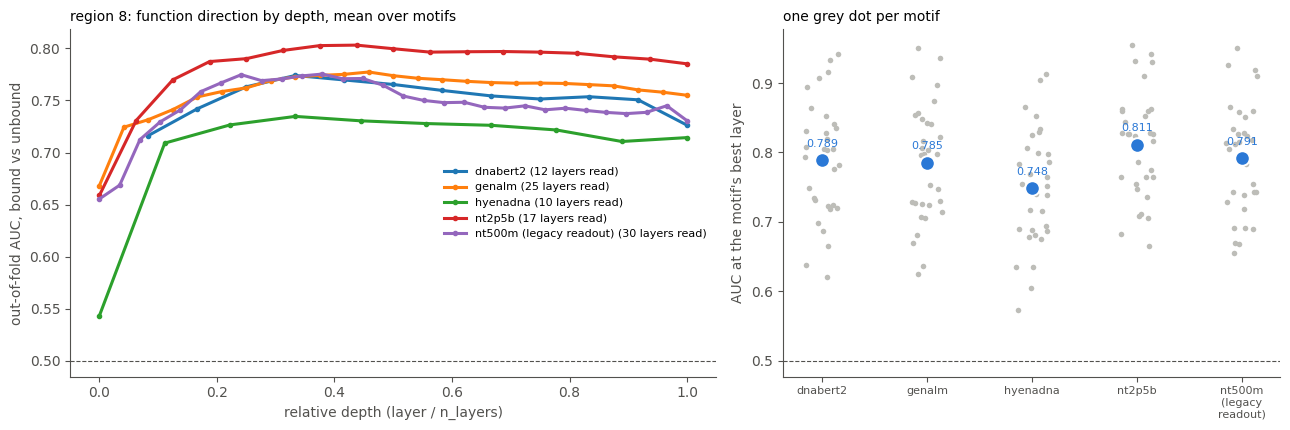


--- where each model peaks (mean over motifs)
                  model  layer  depth   auc
               dnabert2      4  0.333 0.774
                 genalm     11  0.458 0.777
               hyenadna      3  0.333 0.735
                 nt2p5b     14  0.438 0.803
nt500m (legacy readout)     11  0.379 0.775


In [8]:
WORK_DIR = "/content/drive/MyDrive/GitHub/Biological-Foundation-Model/Notebooks/EP Pair Evaluation/per_occurrence/motif_token_study"
import os, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

C = json.load(open(f"{WORK_DIR}/config.json"))
REGION = 8
REG = {0: "fcav_pgc_hk_r0", 8: "fcav_pgc_hk", 20: "fcav_pgc_hk_r20"}
SRC, XM = f"{WORK_DIR}/{REG[REGION]}", f"{WORK_DIR}/fcav_xm"
LEGACY = {0: "fcav_pgc_hk_lr_r0", 8: "fcav_pgc_hk_lr", 20: "fcav_pgc_hk_lr_r20"}[REGION]
INK = "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": INK,
                     "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK})
pd.set_option("display.width", 250)

runs = {d[:-len(f"_r{REGION}")]: f"{XM}/{d}/fits" for d in sorted(os.listdir(XM)) if d.endswith(f"_r{REGION}")}
runs["nt500m (legacy readout)"] = f"{WORK_DIR}/{LEGACY}/fits"
rows = []
for tag, p in runs.items():
    if not os.path.isdir(p):
        continue
    for f in sorted(os.listdir(p)):
        if not f.endswith(".npz"):
            continue
        z = np.load(f"{p}/{f}", allow_pickle=False)
        a = z["auc"]
        lids = z["layers"] if "layers" in z else np.arange(len(a))
        nl = int(z["n_layers"]) if "n_layers" in z else len(a) - 1    # total depth, not the number fitted
        for li, v in zip(lids, a):
            rows.append({"model": tag, "motif": f[:-4], "layer": int(li), "depth": float(li) / nl, "auc": float(v)})
A = pd.DataFrame(rows)
assert len(A), "no fits found; run Section 2"
A.to_csv(f"{XM}/auc_by_layer_r{REGION}.csv", index=False)
_curve = A.groupby(["model", "layer"])["auc"].mean()
print(pd.DataFrame({"motifs": A.groupby("model")["motif"].nunique(),
                    "layers read": A.groupby("model")["layer"].nunique(),
                    "best mean-over-motifs AUC": _curve.groupby("model").max()}).to_string(float_format=lambda x: f"{x:.3f}"))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1.3, 1]})
for tag, g in A.groupby("model"):
    t = g.groupby("depth")["auc"].mean()
    ax[0].plot(t.index, t.values, lw=2.2, marker="o", ms=3, label=f"{tag} ({g['layer'].nunique()} layers read)")
ax[0].axhline(0.5, c=INK, lw=.8, ls="--")
ax[0].set_xlabel("relative depth (layer / n_layers)"); ax[0].set_ylabel("out-of-fold AUC, bound vs unbound")
ax[0].set_title(f"region {REGION}: function direction by depth, mean over motifs", loc="left", fontsize=10)
ax[0].legend(frameon=False, fontsize=8)

best = A.loc[A.groupby(["model", "motif"])["auc"].idxmax()]
tags = list(best["model"].unique())
g = np.random.default_rng(0)
for i, tag in enumerate(tags):
    v = best[best.model == tag]["auc"].values
    ax[1].scatter(i + g.uniform(-.16, .16, len(v)), v, s=16, c="#bdbdb8", lw=0, zorder=2)
    ax[1].scatter([i], [v.mean()], s=110, c="#2a78d6", zorder=3, edgecolor="white", lw=1.4)
    ax[1].text(i, v.mean() + .02, f"{v.mean():.3f}", ha="center", fontsize=8, color="#2a78d6")
ax[1].axhline(0.5, c=INK, lw=.8, ls="--")
ax[1].set_xticks(range(len(tags)), [t.replace(" ", "\n") for t in tags], fontsize=8)
ax[1].set_ylabel("AUC at the motif's best layer")
ax[1].set_title("one grey dot per motif", loc="left", fontsize=10)
plt.tight_layout(); plt.savefig(f"{XM}/auc_by_depth_r{REGION}.png", dpi=150, bbox_inches="tight"); plt.show()

print("\n--- where each model peaks (mean over motifs)")
pk = A.groupby(["model", "layer", "depth"])["auc"].mean().reset_index()
print(pk.loc[pk.groupby("model")["auc"].idxmax()].to_string(index=False, float_format=lambda x: f"{x:.3f}"))

## 3.2 Handing it to the hit-selection notebook

`Hit Selection - Function CAV vs PWM, Regions 0 8 20.ipynb` reads a region as `REG[r] = (source_dir, fits_dir)` and
takes `dec_hit` from the fits. The directories written here have the same shape, so the whole cross-model comparison
against `motifbreakR` is one edit there:

```python
REG = {8: ("fcav_pgc_hk", "fcav_xm/hyenadna_r8")}      # instead of ("fcav_pgc_hk", "fcav_pgc_hk_lr")
```

The cell below checks that handover before you go there — same hits, same order, finite logits — and prints the layer
each model would want as `LP`, since `LP = 24` was chosen for a 29-layer model and means nothing to an 8-layer one.

In [9]:
import pandas as pd
MWJ = json.load(open(f"{SRC}/mpra_windows.json"))
HID_ALL = {h["hit_id"] for h in MWJ["hits"]}
rows = []
for tag, p in runs.items():
    if not os.path.isdir(p):
        continue
    hid, nl, bad = [], None, []
    for f in sorted(os.listdir(p)):
        if not f.endswith(".npz"):
            continue
        z = np.load(f"{p}/{f}", allow_pickle=False)
        if "dec_hit" not in z:
            bad.append(f[:-4]); continue
        hid += list(z["hit_id"])
        nl = int(z["n_layers"]) if "n_layers" in z else z["dec_hit"].shape[1] - 1
        if not np.isfinite(z["dec_hit"]).all():
            bad.append(f[:-4] + " (non-finite)")
    a = A[A.model == tag]
    t = a.groupby("layer")["auc"].mean()
    rows.append({"model": tag, "hits with a direction": len(hid), "unknown hit ids": len(set(hid) - HID_ALL),
                 "n_layers": nl, "best layer by AUC": int(t.idxmax()), "relative depth": t.idxmax() / nl,
                 "its AUC": t.max(), "problems": ", ".join(bad) if bad else ""})
T = pd.DataFrame(rows).set_index("model")
print(T.to_string(float_format=lambda x: f"{x:.3f}"))
assert (T["unknown hit ids"] == 0).all(), "a fit refers to hit ids this region does not have"
print(f"\nfor the hit-selection notebook, region {REGION}:")
for tag, p in runs.items():
    if os.path.isdir(p) and tag in T.index:
        print(f'  REG = {{{REGION}: ("{REG[REGION]}", "{p.replace(WORK_DIR + "/", "")[:-5]}")}}   '
              f'# {tag}, and set LP = {T.loc[tag, "best layer by AUC"]}')

                         hits with a direction  unknown hit ids  n_layers  best layer by AUC  relative depth  its AUC problems
model                                                                                                                         
dnabert2                                    33                0        12                  4           0.333    0.774         
genalm                                      33                0        24                 11           0.458    0.777         
hyenadna                                    33                0         9                  3           0.333    0.735         
nt2p5b                                      33                0        32                 14           0.438    0.803         
nt500m (legacy readout)                     33                0        29                 11           0.379    0.775         

for the hit-selection notebook, region 8:
  REG = {8: ("fcav_pgc_hk", "fcav_xm/dnabert2_r8")}   # dnabert2, an

## 3.3 motifbreakR with and without each model's CAV

The four rules of `Hit Selection` (cell "Does the CAV improve motifbreakR?"), run once per model on the **same SNVs and
the same hits** (the hits that every model has a direction for):

| rule | motif used per SNV | prediction |
|---|---|---|
| motifbreakR | largest \|alleleDiff\| | alleleDiff |
| motifbreakR × w(P) | largest \|alleleDiff\| | alleleDiff × w(P) |
| CAV-chosen motifbreakR | highest P(bound) | alleleDiff |
| CAV-chosen motifbreakR × w(P) | highest P(bound) | alleleDiff × w(P) |

w(P) = sigmoid(20 (P − 0.75)), as there. Layer: each model's best layer by mean AUC (3.1), picked without looking at the
MPRA; the legacy nt500m row uses L24 as Hit Selection did, so its numbers should match Hit Selection's region-8 column.
Nulls: P shuffled across hits (N1) and within motif (N2). Only region 8, so these are one-region numbers, not the
three-region means of Hit Selection.

Caveat: 0.75 / 20 were tuned on nt500m. A model whose P sits lower overall gets its predictions shrunk towards 0 by the
gate for that reason alone; the "P > 0.75" column shows how much of each model's P is above the gate.

33 hits have a direction in every model (dnabert2: 33, genalm: 33, hyenadna: 33, nt2p5b: 33, nt500m (legacy readout): 33)
region 8: 459 SNVs inside these hits; motifbreakR reports 421 pairs with a covering hit (227 SNVs)

=== region 8: motifbreakR with and without each model's CAV; w = sigmoid(20 (P - 0.75)); nulls 1000 shuffles of P (N1 across hits, N2 within motif)

--- Spearman signed
                                                                       Spearman signed  vs motifbreakR   p N1   p N2
model                   layer  P > 0.75 rule                                                                        
dnabert2                L4/12  0.060606 motifbreakR                             +0.197                              
                                        motifbreakR × w(P)                      +0.158          -0.039 +0.280 +0.458
                                        CAV-chosen motifbreakR                  +0.171          -0.027 +0.522 +0.458
                        

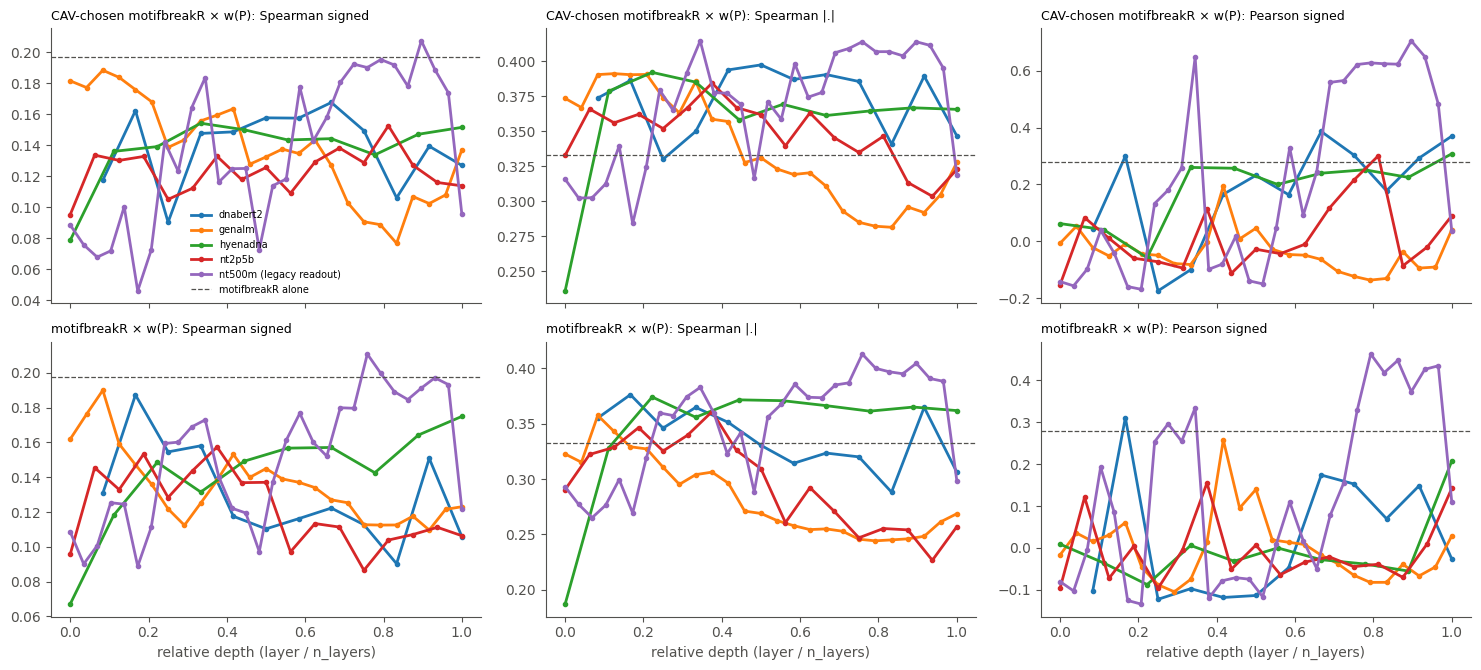

In [10]:
import re
from scipy import stats
MID, K = 0.75, 20                     # w(P) = sigmoid(K (P - MID)), as in Hit Selection
MBR_THRESH, MBR_NEUT = 0.85, 0.4      # motifbreakR default threshold and "neutral" cut
N_PERM = 1000
LP_FIX = {"nt500m (legacy readout)": 24}   # the layer Hit Selection used; every other model: its best AUC layer
METRICS = ["Spearman signed", "Spearman |.|", "Pearson signed"]
MC_RULES = ["motifbreakR", "motifbreakR × w(P)", "CAV-chosen motifbreakR", "CAV-chosen motifbreakR × w(P)"]
wfun = lambda x: 1 / (1 + np.exp(-K * (x - MID)))


def scores(pred, y):
    if np.std(pred) == 0:
        return np.array([np.nan] * 3)
    return np.array([stats.spearmanr(pred, y)[0], stats.spearmanr(np.abs(pred), np.abs(y))[0], stats.pearsonr(pred, y)[0]])


# ---------- P(bound) per hit and layer, every model ----------
PB, NL = {}, {}
for tag, p in runs.items():
    if not os.path.isdir(p):
        continue
    dec = []
    for f in sorted(os.listdir(p)):
        if f.endswith(".npz"):
            z = np.load(f"{p}/{f}", allow_pickle=False)
            if "dec_hit" in z and len(z["hit_id"]):
                dec.append(pd.DataFrame(z["dec_hit"], index=z["hit_id"], columns=[int(l) for l in z["layers"]]))
                NL[tag] = int(z["n_layers"]) if "n_layers" in z else z["dec_hit"].shape[1] - 1
    if dec:
        PB[tag] = 1 / (1 + np.exp(-pd.concat(dec)))
HS = np.array(sorted(set.intersection(*(set(v.index) for v in PB.values()))))
print(f"{len(HS)} hits have a direction in every model ({', '.join(f'{t}: {len(v)}' for t, v in PB.items())})")

# ---------- SNV x hit rows on those hits (as Hit Selection's main cell) ----------
hits = pd.read_csv(f"{SRC}/hits.csv").set_index("hit_id")
snv = pd.read_csv(f"{SRC}/snvs.csv")
q = pd.read_csv(f"{SRC}/snv_hit_dpwm.csv")
q = q[q["hit_id"].isin(HS)].sort_values(["snv", "hit_id"]).reset_index(drop=True)
sn = q["snv"].values
st = np.r_[0, np.flatnonzero(sn[1:] != sn[:-1]) + 1]
hi = np.searchsorted(HS, q["hit_id"].values)
y = snv.loc[sn[st], "log2FC"].values
n_snv = len(st)
MOT = hits.loc[HS, "motif"].values

# ---------- motifbreakR (default scoring, as Hit Selection) ----------
def _read_meme(path):
    out, name, rows_, ns = {}, None, [], 20
    for line in open(path):
        t = line.split()
        if line.startswith("MOTIF"):
            if name is not None and name not in out:
                out[name] = (np.array(rows_), ns)
            name, rows_, ns = (t[2] if len(t) > 2 else t[1]), [], 20
        elif line.startswith("letter-probability"):
            m = re.search(r"nsites=\s*([0-9.]+)", line)
            ns = float(m.group(1)) if m else 20
        elif name is not None and len(t) == 4 and all(re.fullmatch(r"[0-9.eE+-]+", x) for x in t):
            rows_.append([float(x) for x in t])
    if name is not None and name not in out:
        out[name] = (np.array(rows_), ns)
    return out


MBR_MATS = {}
for name, (f, ns) in _read_meme(C["meme_path"]).items():
    f = f / f.sum(1, keepdims=True)
    pp = (f * ns + 0.25) / (ns + 1)
    S = pp * (pp.max(1) - pp.min(1))[:, None]
    S = np.vstack([S.T, np.zeros(len(S))]).T
    MBR_MATS[name] = (S, S[::-1][:, [3, 2, 1, 0, 4]], S[:, :4].min(1).sum(), S[:, :4].max(1).sum())
ENC = {"A": 0, "C": 1, "G": 2, "T": 3}
base = {}
for h in MWJ["hits"]:
    for i, b in enumerate(h["window"]):
        base.setdefault(h["start"] - C["motif_offset"] + i, b)
lo = min(base)
seq = np.array([ENC.get(base.get(x, "N"), 4) for x in range(lo, max(base) + 1)])
s_ = snv.loc[sn[st]]
pos, ref, alt = s_["local"].values - lo, s_["ref"].map(ENC).values, s_["alt"].map(ENC).values
assert (seq[pos] == ref).all(), "rebuilt sequence disagrees with the SNV reference bases"
out = []
for m in sorted(set(MOT)):
    if m not in MBR_MATS:
        continue
    S, Sr, smin, smax = MBR_MATS[m]
    w = len(S)
    n = len(seq) - w + 1
    idx = np.arange(n)[:, None] + np.arange(w)[None, :]
    f_fwd, f_rev = S[np.arange(w), seq[idx]].sum(1), Sr[np.arange(w), seq[idx]].sum(1)
    stw = pos[:, None] - np.arange(w)[None, :]
    k = np.broadcast_to(np.arange(w), stw.shape)
    ok = (stw >= 0) & (stw < n)
    stc = np.clip(stw, 0, n - 1)
    ref_f, ref_r = np.where(ok, f_fwd[stc], -np.inf), np.where(ok, f_rev[stc], -np.inf)
    alt_f = ref_f + np.where(ok, S[k, alt[:, None]] - S[k, ref[:, None]], 0)
    alt_r = ref_r + np.where(ok, Sr[k, alt[:, None]] - Sr[k, ref[:, None]], 0)
    sr, sa = np.maximum(ref_f, ref_r).max(1), np.maximum(alt_f, alt_r).max(1)
    pr, pa = (sr - smin) / (smax - smin), (sa - smin) / (smax - smin)
    diff = sa - sr
    keep = np.isfinite(sr) & ((pr > MBR_THRESH) | (pa > MBR_THRESH)) & (np.abs(diff) >= MBR_NEUT)
    out += [(i, m, diff[i]) for i in np.flatnonzero(keep)]
t = pd.DataFrame(out, columns=["i", "motif", "alleleDiff"])
t["j"] = np.arange(len(t))
rows_ = pd.DataFrame({"i": np.repeat(np.arange(n_snv), np.diff(np.r_[st, len(sn)])), "motif": MOT[hi], "h": hi})
link = t[["j", "i", "motif"]].merge(rows_, on=["i", "motif"])            # (motifbreakR pair, covering hit)
keep = np.sort(link["j"].unique())
t = t.loc[keep].reset_index(drop=True)
lj, lh = np.searchsorted(keep, link["j"].values), link["h"].values
DIFF, TI = t["alleleDiff"].values, t["i"].values
print(f"region {REGION}: {n_snv} SNVs inside these hits; motifbreakR reports {len(t)} pairs with a covering hit "
      f"({t['i'].nunique()} SNVs)")


def mc_predict(p_hit):
    P = np.full(len(t), -np.inf)
    np.maximum.at(P, lj, p_hit[lh])

    def pick(key, val):
        pred = np.zeros(n_snv)
        o = np.lexsort((-key, TI))
        first = o[np.r_[True, TI[o][1:] != TI[o][:-1]]]
        pred[TI[first]] = val[first]
        return pred

    return {"motifbreakR": pick(np.abs(DIFF), DIFF),
            "motifbreakR × w(P)": pick(np.abs(DIFF), DIFF * wfun(P)),
            "CAV-chosen motifbreakR": pick(P + 1e-9 * np.abs(DIFF), DIFF),
            "CAV-chosen motifbreakR × w(P)": pick(P + 1e-9 * np.abs(DIFF), DIFF * wfun(P))}


GROUPS = [np.flatnonzero(MOT == m) for m in np.unique(MOT)]


def perm_motif(p, rng):
    p = p.copy()
    for g_ in GROUPS:
        p[g_] = p[g_][rng.permutation(len(g_))]
    return p


# ---------- one table: every model at its layer ----------
rng = np.random.default_rng(5)
rows = []
for tag, Pt in PB.items():
    a = A[A.model == tag].groupby("layer")["auc"].mean()
    lp = LP_FIX.get(tag, int(a.idxmax()))
    p = Pt.loc[HS, lp].values
    obs = {k: scores(v, y) for k, v in mc_predict(p).items()}
    n1 = np.array([[scores(v, y) for v in mc_predict(rng.permutation(p)).values()] for _ in range(N_PERM)])
    n2 = np.array([[scores(v, y) for v in mc_predict(perm_motif(p, rng)).values()] for _ in range(N_PERM)])
    for ki, k in enumerate(MC_RULES):
        row = {"model": tag, "layer": f"L{lp}/{NL[tag]}", "P > 0.75": np.mean(p > MID), "rule": k}
        for j, mt in enumerate(METRICS):
            row[mt] = obs[k][j]
            if k != "motifbreakR":
                row[f"{mt}: vs motifbreakR"] = obs[k][j] - obs["motifbreakR"][j]
                row[f"{mt}: p N1"] = np.mean(n1[:, ki, j] >= obs[k][j])
                row[f"{mt}: p N2"] = np.mean(n2[:, ki, j] >= obs[k][j])
        rows.append(row)
MX = pd.DataFrame(rows).set_index(["model", "layer", "P > 0.75", "rule"])
MX.to_csv(f"{XM}/motifbreakr_plus_cav_r{REGION}.csv")
print(f"\n=== region {REGION}: motifbreakR with and without each model's CAV; w = sigmoid({K} (P - {MID})); "
      f"nulls {N_PERM} shuffles of P (N1 across hits, N2 within motif)\n")
for mt in METRICS:
    cols = [mt] + [c for c in MX.columns if c.startswith(mt + ":")]
    print(f"--- {mt}")
    print(MX[cols].rename(columns=lambda c: c.replace(mt + ": ", "")).to_string(float_format=lambda x: f"{x:+.3f}", na_rep=""))
    print()

# ---------- every layer: the CAV rules against motifbreakR, by relative depth ----------
rows = []
for tag, Pt in PB.items():
    for l in Pt.columns:
        for k, v in mc_predict(Pt.loc[HS, l].values).items():
            rows.append({"model": tag, "layer": l, "depth": l / NL[tag], "rule": k, **dict(zip(METRICS, scores(v, y)))})
ML = pd.DataFrame(rows)
ML.to_csv(f"{XM}/motifbreakr_plus_cav_by_layer_r{REGION}.csv", index=False)
SHOW = ["CAV-chosen motifbreakR × w(P)", "motifbreakR × w(P)"]
fig, ax = plt.subplots(len(SHOW), 3, figsize=(15, 3.4 * len(SHOW)), sharex=True)
mbr = ML[ML.rule == "motifbreakR"].iloc[0]
for i, rule in enumerate(SHOW):
    for j, mt in enumerate(METRICS):
        a_ = ax[i, j]
        for tag, g_ in ML[ML.rule == rule].groupby("model"):
            a_.plot(g_["depth"], g_[mt], lw=2, marker="o", ms=3, label=tag)
        a_.axhline(mbr[mt], c=INK, lw=.9, ls="--", label="motifbreakR alone")
        a_.set_title(f"{rule}: {mt}", loc="left", fontsize=9)
        if i == len(SHOW) - 1:
            a_.set_xlabel("relative depth (layer / n_layers)")
ax[0, 0].legend(frameon=False, fontsize=7)
plt.tight_layout(); plt.savefig(f"{XM}/motifbreakr_plus_cav_by_depth_r{REGION}.png", dpi=150, bbox_inches="tight"); plt.show()

## 3.4 P(bound) of every motif hit along the region

Two rows on one position axis. **Top:** the measured log2FC, averaged over the SNVs at each position. **Bottom:** every
motif hit in the region, drawn as a bar over its bases at the height of its P(bound) from `TAG`'s CAV, labelled with
the motif. Dashed line: 0.75, the gate midpoint of w(P). `LP = None` uses the model's best layer by mean AUC (3.1).

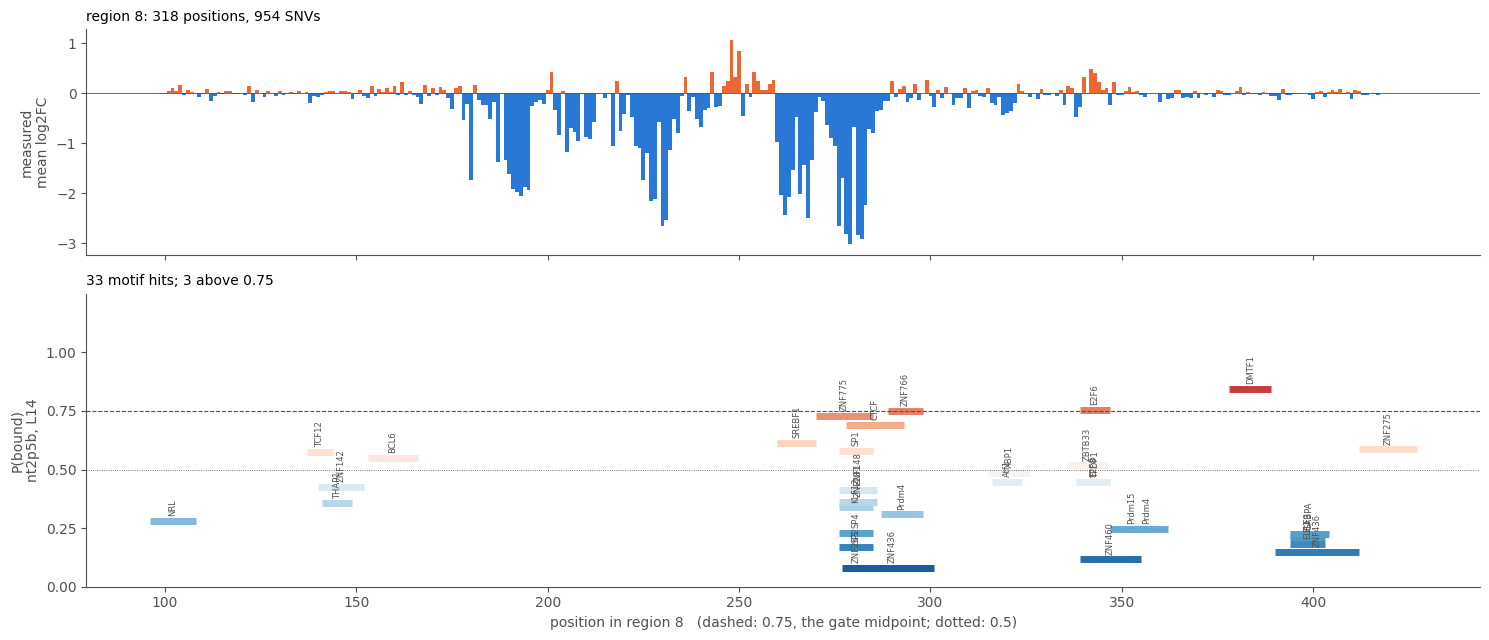

     motif  start  end     P
31   DMTF1    378  389 0.844
75    E2F6    339  347 0.755
54  ZNF766    289  298 0.750
70  ZNF775    270  285 0.730
64    CTCF    278  293 0.691
0   SREBF1    260  270 0.613
52  ZNF275    412  427 0.587
11     SP1    276  285 0.579
55   TCF12    137  144 0.576
25    BCL6    153  166 0.551
51  ZBTB33    336  346 0.519
28    XBP1    315  326 0.486
63    Atf1    316  324 0.449
7     E2F8    338  347 0.446
22   TFDP1    339  347 0.445
61  ZNF142    140  152 0.427
12  ZNF148    276  286 0.413
5   ZNF281    276  286 0.361
21   THAP1    141  149 0.356
56   KLF12    276  285 0.339
58   Prdm4    287  298 0.308
42     NRL     96  108 0.281
10  Prdm15    347  358 0.248
33   Prdm4    351  362 0.248
13     SP4    276  285 0.231
73   GABPA    394  404 0.223
67    ELF3    394  403 0.212
41    ELF1    394  403 0.182
43     SP2    276  285 0.168
3   ZNF436    390  412 0.148
48  ZNF460    339  355 0.117
40  ZNF263    277  284 0.081
60  ZNF436    279  301 0.079


In [11]:
TAG = "nt2p5b"            # any model in fcav_xm, or "nt500m (legacy readout)"
LP = None                 # layer of P(bound); None = TAG's best layer by mean AUC in 3.1

dec = []
for f in sorted(os.listdir(runs[TAG])):
    if f.endswith(".npz"):
        z = np.load(f"{runs[TAG]}/{f}", allow_pickle=False)
        if "dec_hit" in z and len(z["hit_id"]):
            dec.append(pd.DataFrame(z["dec_hit"], index=z["hit_id"], columns=[int(l) for l in z["layers"]]))
Pn = 1 / (1 + np.exp(-pd.concat(dec)))
lp = LP if LP is not None else int(A[A.model == TAG].groupby("layer")["auc"].mean().idxmax())
hits = pd.read_csv(f"{SRC}/hits.csv").set_index("hit_id")
snv = pd.read_csv(f"{SRC}/snvs.csv")
hh = hits.loc[Pn.index, ["motif", "start", "end"]].assign(P=Pn[lp].values).sort_values(["start", "end"])
y_pos = snv.groupby("local")["log2FC"].mean()

cm, nm = plt.get_cmap("RdBu_r"), plt.Normalize(0, 1)
fig, ax = plt.subplots(2, 1, figsize=(15, 6.5), sharex=True, gridspec_kw={"height_ratios": [1, 1.3]})
ax[0].bar(y_pos.index, y_pos.values, width=1, color=np.where(y_pos.values < 0, "#2a78d6", "#eb6834"))
ax[0].axhline(0, c=INK, lw=.6)
ax[0].set_ylabel("measured\nmean log2FC")
ax[0].set_title(f"region {REGION}: {len(y_pos)} positions, {len(snv)} SNVs", loc="left", fontsize=10)
for _, h in hh.iterrows():
    ax[1].plot([h["start"], h["end"]], [h["P"], h["P"]], lw=5, c=cm(nm(h["P"])), solid_capstyle="butt")
    ax[1].text((h["start"] + h["end"]) / 2, h["P"] + 0.02, h["motif"], ha="center", va="bottom", fontsize=6,
               rotation=90, color=INK)
ax[1].axhline(0.75, c=INK, lw=.8, ls="--")
ax[1].axhline(0.5, c=INK, lw=.6, ls=":")
ax[1].set_ylim(0, 1.25); ax[1].set_yticks([0, .25, .5, .75, 1])
ax[1].set_ylabel(f"P(bound)\n{TAG}, L{lp}")
ax[1].set_xlabel(f"position in region {REGION}   (dashed: 0.75, the gate midpoint; dotted: 0.5)")
ax[1].set_title(f"{len(hh)} motif hits; {int((hh['P'] > 0.75).sum())} above 0.75", loc="left", fontsize=10)
plt.tight_layout()
plt.savefig(f"{XM}/pbound_track_{TAG.split(' ')[0]}_L{lp}_r{REGION}.png", dpi=150, bbox_inches="tight"); plt.show()
print(hh.sort_values("P", ascending=False).to_string(float_format=lambda x: f"{x:.3f}"))

## End

Read Section 2 first. If a model's curve sits on 0.5 there is no function direction to gate with and its
`motifbreakR` comparison will be noise, however it comes out. If a curve does rise, the shape is the result worth
reporting: nt500m's function direction peaks late, and whether a causal model with one eighth the depth puts it at
the same **relative** place is the question this notebook exists to answer.